In [8]:
import pandas as pd
import ast

# ============================================================
# CHARGEMENT DU DATASET
# ============================================================

SEQUENCE_FILE = "output/hdfs_data/sequences_drain3.csv"

df = pd.read_csv(SEQUENCE_FILE)

print(f"Dataset chargé : {len(df):,} séquences")

# ============================================================
# CONVERSION DE EventSequence
# ============================================================

first = str(df["EventSequence"].iloc[0])

if first.startswith("["):
    df["EventSequence"] = df["EventSequence"].apply(ast.literal_eval)

elif "|" in first and "E" not in first:
    df["EventSequence"] = df["EventSequence"].apply(
        lambda x: [int(i) for i in str(x).split("|") if i]
    )

elif "E" in first:
    df["EventSequence"] = df["EventSequence"].apply(
        lambda x: [int(i.replace("E", "")) for i in str(x).split("|") if i]
    )

# ============================================================
# SUPPRESSION DES COLONNES INUTILES
# ============================================================

df.drop(
    columns=["BlockId", "EventTemplates"],
    errors="ignore",
    inplace=True
)

# ============================================================
# INFORMATIONS
# ============================================================

print(df.head())

print("\nDistribution des labels :")
print(df["Label"].value_counts())

print("\nValeurs manquantes :")
print(df.isnull().sum())

Dataset chargé : 575,061 séquences
                                       EventSequence    Label  NumEvents  \
0  [E1, E2, E1, E1, E3, E3, E4, E4, E3, E4, E5, E...   Normal        269   
1  [E1, E1, E2, E1, E3, E4, E3, E4, E3, E4, E5, E...   Normal         22   
2  [E1, E2, E1, E1, E3, E4, E3, E4, E3, E4, E10, ...  Anomaly        223   
3  [E1, E2, E1, E1, E3, E4, E3, E4, E3, E4, E5, E...   Normal         22   
4  [E1, E1, E2, E1, E3, E4, E3, E4, E3, E4, E5, E...   Normal         38   

     Duration  NumINFO  NumWARN  NumERROR  
0      3802.0      269        0         0  
1      3802.0       22        0         0  
2      3797.0      222        1         0  
3  31500048.0       22        0         0  
4  31500183.0       23       15         0  

Distribution des labels :
Label
Normal     558223
Anomaly     16838
Name: count, dtype: int64

Valeurs manquantes :
EventSequence    0
Label            0
NumEvents        0
Duration         0
NumINFO          0
NumWARN          0
NumERROR     

In [59]:
# ============================================================
# 2. PRÉTRAITEMENT DES DONNÉES
# ============================================================

import re
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
import numpy as np


# ------------------------------------------------------------
# 2.1 Copie du dataset
# ------------------------------------------------------------

df_processed = df.copy()

# ------------------------------------------------------------
# 2.2 Conversion du Label
# ------------------------------------------------------------

print("\n[1] Conversion des labels")

df_processed["Label"] = (
    df_processed["Label"]
    .map({"Normal": 0, "Anomaly": 1})
    .astype(np.int8)
)

print("   ✓ Labels convertis")

# ------------------------------------------------------------
# 2.3 Suppression des colonnes inutiles
# ------------------------------------------------------------

print("\n[2] Suppression des colonnes inutiles")

df_processed.drop(columns=["BlockId", "EventTemplates", "NumERROR"], errors="ignore", inplace=True)

# ------------------------------------------------------------
# 2.4 Conversion des EventSequence
# ------------------------------------------------------------

print("\n[3] Conversion des séquences")

def convert_sequence(seq):
    return [int(re.sub(r"\D", "", e)) for e in seq]

df_processed["EventSequence"] = (
    df_processed["EventSequence"]
    .apply(convert_sequence)
)

print("   ✓ EventSequence convertie")


# ------------------------------------------------------------
# 2.5 Transformation de Duration
# ------------------------------------------------------------

print("\n[4] Transformation logarithmique de Duration")

df_processed["Duration"] = np.log1p(df_processed["Duration"])

print("   ✓ Duration transformée")

# ------------------------------------------------------------
# 2.6 Préparation des séquences
# ------------------------------------------------------------

print("\n[5] Préparation des séquences")

sequences = df_processed["EventSequence"].tolist()

all_events = set()

for seq in sequences:
    all_events.update(seq)

vocab_size = max(all_events) + 1

lengths = [len(seq) for seq in sequences]

max_seq_len = int(np.percentile(lengths, 99))

print(f"   Evénements uniques : {len(all_events)}")
print(f"   Taille vocabulaire : {vocab_size}")
print(f"   Longueur max utilisée : {max_seq_len}")

# ------------------------------------------------------------
# Padding
# ------------------------------------------------------------

def pad_sequences_manual(sequences, maxlen, pad_value=0):

    padded = []

    for seq in sequences:

        if len(seq) >= maxlen:
            padded.append(seq[:maxlen])

        else:
            padded.append(
                seq + [pad_value] * (maxlen - len(seq))
            )

    return np.array(padded, dtype=np.int64)

X_sequences = pad_sequences_manual(
    sequences,
    max_seq_len,
    pad_value=0
)

print(f"   ✓ Shape : {X_sequences.shape}")

# ------------------------------------------------------------
# 2.7 Features numériques
# ------------------------------------------------------------

print("\n[6] Features numériques")

numeric_features = [
    "NumEvents",
    "Duration",
    "NumINFO",
    "NumWARN"
]
X_numeric = df_processed[numeric_features].values

print("   Features utilisées :")
print("   ", numeric_features)

print(f"   ✓ Shape : {X_numeric.shape}")

# ------------------------------------------------------------
# 2.8 Labels
# ------------------------------------------------------------

y = df_processed["Label"].values

print("\n[7] Labels")

print("Distribution :")

print(np.bincount(y))

# ------------------------------------------------------------
# 2.9 Split sans Data Leakage
# ------------------------------------------------------------

print("\n[8] Création des ensembles (sans fuite de données)")

# Créer une clé unique pour chaque séquence
df_processed["SequenceKey"] = df_processed["EventSequence"].apply(tuple)

# Une ligne par séquence unique
unique_sequences = (
    df_processed[["SequenceKey", "Label"]]
    .drop_duplicates()
)

# Séparation Train / Temp
train_keys, temp_keys = train_test_split(
    unique_sequences,
    test_size=0.30,
    random_state=42,
    stratify=unique_sequences["Label"]
)

# Séparation Validation / Test
val_keys, test_keys = train_test_split(
    temp_keys,
    test_size=0.50,
    random_state=42,
    stratify=temp_keys["Label"]
)

# Reconstruction des ensembles
train_df = df_processed.merge(
    train_keys[["SequenceKey"]],
    on="SequenceKey"
)

val_df = df_processed.merge(
    val_keys[["SequenceKey"]],
    on="SequenceKey"
)

test_df = df_processed.merge(
    test_keys[["SequenceKey"]],
    on="SequenceKey"
)

print(f"Train : {len(train_df):,}")
print(f"Validation : {len(val_df):,}")
print(f"Test : {len(test_df):,}")

# ============================================================
# Préparation des séquences
# ============================================================

X_seq_train = pad_sequences_manual(
    train_df["EventSequence"].tolist(),
    max_seq_len
)

X_seq_val = pad_sequences_manual(
    val_df["EventSequence"].tolist(),
    max_seq_len
)

X_seq_test = pad_sequences_manual(
    test_df["EventSequence"].tolist(),
    max_seq_len
)

# ============================================================
# Features numériques
# ============================================================

X_num_train = train_df[numeric_features].values
X_num_val = val_df[numeric_features].values
X_num_test = test_df[numeric_features].values

# ============================================================
# Normalisation
# ============================================================

scaler = StandardScaler()

X_num_train = scaler.fit_transform(X_num_train)
X_num_val = scaler.transform(X_num_val)
X_num_test = scaler.transform(X_num_test)

# ============================================================
# Labels
# ============================================================

y_train = train_df["Label"].values
y_val = val_df["Label"].values
y_test = test_df["Label"].values

# Nettoyage
train_df.drop(columns=["SequenceKey"], inplace=True)
val_df.drop(columns=["SequenceKey"], inplace=True)
test_df.drop(columns=["SequenceKey"], inplace=True)
df_processed.drop(columns=["SequenceKey"], inplace=True)

print("\nRépartition finale")
print(f"Train      : {len(y_train):,}")
print(f"Validation : {len(y_val):,}")
print(f"Test       : {len(y_test):,}")



# ============================================================
# 3. DATASET PYTORCH
# ============================================================

class HDFSAnomalyDataset(Dataset):

    def __init__(self, sequences, numeric_features, labels):

        self.sequences = torch.LongTensor(sequences)
        self.numeric = torch.FloatTensor(numeric_features)
        self.labels = torch.FloatTensor(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        return {
            "sequence": self.sequences[idx],
            "numeric": self.numeric[idx],
            "label": self.labels[idx]
        }

train_dataset = HDFSAnomalyDataset(
    X_seq_train,
    X_num_train,
    y_train
)

val_dataset = HDFSAnomalyDataset(
    X_seq_val,
    X_num_val,
    y_val
)

test_dataset = HDFSAnomalyDataset(
    X_seq_test,
    X_num_test,
    y_test
)

batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print(f"\n[9] DataLoaders créés (batch_size={batch_size})")


[1] Conversion des labels
   ✓ Labels convertis

[2] Suppression des colonnes inutiles

[3] Conversion des séquences
   ✓ EventSequence convertie

[4] Transformation logarithmique de Duration
   ✓ Duration transformée

[5] Préparation des séquences
   Evénements uniques : 47
   Taille vocabulaire : 48
   Longueur max utilisée : 33
   ✓ Shape : (575061, 33)

[6] Features numériques
   Features utilisées :
    ['NumEvents', 'Duration', 'NumINFO', 'NumWARN']
   ✓ Shape : (575061, 4)

[7] Labels
Distribution :
[558223  16838]

[8] Création des ensembles (sans fuite de données)
Train : 434,578
Validation : 81,363
Test : 59,166

Répartition finale
Train      : 434,578
Validation : 81,363
Test       : 59,166

[9] DataLoaders créés (batch_size=64)


In [60]:
# ============================================================
# PARTIE 3 : DATASET PYTORCH
# ============================================================

class HDFSAnomalyDataset(Dataset):

    def __init__(self, sequences, numeric, labels):

        self.sequences = torch.LongTensor(sequences)
        self.numeric = torch.FloatTensor(numeric)
        self.labels = torch.FloatTensor(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        return {
            "sequence": self.sequences[idx],
            "numeric": self.numeric[idx],
            "label": self.labels[idx]
        }

train_dataset = HDFSAnomalyDataset(X_seq_train, X_num_train, y_train)
val_dataset = HDFSAnomalyDataset(X_seq_val, X_num_val, y_val)
test_dataset = HDFSAnomalyDataset(X_seq_test, X_num_test, y_test)

batch_size = 64

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [61]:
# ============================================================
# PARTIE 4 : CONSTRUCTION DU MODÈLE BiLSTM
# ============================================================

import torch
import torch.nn as nn

print("=" * 70)
print("PARTIE 4 : CONSTRUCTION DU MODÈLE BiLSTM")
print("=" * 70)

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device : {device}")

# ------------------------------------------------------------
# Modèle BiLSTM
# ------------------------------------------------------------

class BiLSTMClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=64,
        hidden_dim=64,
        num_layers=2,
        numeric_dim=4,
        dropout=0.20
    ):

        super().__init__()

        # =====================================================
        # Embedding
        # =====================================================

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=0
        )

        # =====================================================
        # BiLSTM
        # =====================================================

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout
        )

        # =====================================================
        # Branche des variables numériques
        # =====================================================

        self.numeric_branch = nn.Sequential(

            nn.Linear(numeric_dim, 16),
            nn.ReLU(),
            nn.Dropout(dropout)

        )

        # =====================================================
        # Classifieur
        # =====================================================

        self.classifier = nn.Sequential(

            nn.Linear(hidden_dim * 2 + 16, 64),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(32, 1)

        )

    # =========================================================
    # Propagation avant
    # =========================================================

    def forward(self, sequence, numeric):

        # Embedding
        x = self.embedding(sequence)

        # BiLSTM
        _, (hidden, _) = self.lstm(x)

        # États cachés avant et arrière
        sequence_features = torch.cat(
            (hidden[-2], hidden[-1]),
            dim=1
        )

        # Variables numériques
        numeric_features = self.numeric_branch(numeric)

        # Fusion
        features = torch.cat(
            (sequence_features, numeric_features),
            dim=1
        )

        # Classification
        output = self.classifier(features)

        return output.squeeze(1)

# ------------------------------------------------------------
# Création du modèle
# ------------------------------------------------------------

model = BiLSTMClassifier(

    vocab_size=vocab_size,

    embedding_dim=64,

    hidden_dim=64,

    num_layers=2,

    numeric_dim=4,

    dropout=0.30

).to(device)

# ------------------------------------------------------------
# Informations sur le modèle
# ------------------------------------------------------------

print(model)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nNombre total de paramètres :", f"{total_params:,}")
print("Paramètres entraînables    :", f"{trainable_params:,}")

print("\n✓ Modèle créé avec succès.")

PARTIE 4 : CONSTRUCTION DU MODÈLE BiLSTM
Device : cpu
BiLSTMClassifier(
  (embedding): Embedding(48, 64, padding_idx=0)
  (lstm): LSTM(64, 64, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (numeric_branch): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
  )
  (classifier): Sequential(
    (0): Linear(in_features=144, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)

Nombre total de paramètres : 180,433
Paramètres entraînables    : 180,433

✓ Modèle créé avec succès.


In [62]:
# ============================================================
# PARTIE 5 : LOSS, OPTIMIZER ET EARLY STOPPING
# ============================================================

print("=" * 70)
print("PARTIE 5 : LOSS, OPTIMIZER ET EARLY STOPPING")
print("=" * 70)

from sklearn.utils.class_weight import compute_class_weight

# ------------------------------------------------------------
# 1. Calcul des poids des classes
# ------------------------------------------------------------

classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

print("\nPoids des classes :")

for c, w in zip(classes, class_weights):
    print(f"Classe {c} -> {w:.4f}")

# BCEWithLogitsLoss ne nécessite que le poids de la classe positive

num_normal = np.sum(y_train == 0)
num_anomaly = np.sum(y_train == 1)

pos_weight = torch.tensor(
    num_normal / num_anomaly,
    dtype=torch.float32,
    device=device
)

print(f"\npos_weight = {pos_weight.item():.4f}")

# ------------------------------------------------------------
# 2. Fonction de perte
# ------------------------------------------------------------

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

print("\n✓ BCEWithLogitsLoss créée")

# ------------------------------------------------------------
# 3. Optimizer
# ------------------------------------------------------------

learning_rate = 1e-3

optimizer = optim.AdamW(

    model.parameters(),

    lr=learning_rate,

    weight_decay=1e-5

)

print(f"✓ Adam créé (lr={learning_rate})")

# ------------------------------------------------------------
# 4. Scheduler
# ------------------------------------------------------------

scheduler = optim.lr_scheduler.ReduceLROnPlateau(

    optimizer,

    mode="min",

    factor=0.5,

    patience=2

)

print("✓ Scheduler ReduceLROnPlateau créé")

# ------------------------------------------------------------
# 5. Early Stopping
# ------------------------------------------------------------

class EarlyStopping:

    def __init__(

        self,

        patience=5,

        min_delta=1e-4,

        save_path="best_bilstm_model.pth"

    ):

        self.patience = patience

        self.min_delta = min_delta

        self.best_loss = np.inf

        self.counter = 0

        self.save_path = save_path

        self.early_stop = False

    def __call__(self, val_loss, model):

        if val_loss < self.best_loss - self.min_delta:

            self.best_loss = val_loss

            self.counter = 0

            torch.save(model.state_dict(), self.save_path)

            print("   ✓ Nouveau meilleur modèle sauvegardé")

        else:

            self.counter += 1

            print(f"   EarlyStopping : {self.counter}/{self.patience}")

            if self.counter >= self.patience:

                self.early_stop = True


early_stopping = EarlyStopping(

    patience=5,

    save_path="best_bilstm_model.pth"

)

print("✓ EarlyStopping créé")

# ------------------------------------------------------------
# Résumé
# ------------------------------------------------------------

print("\nRésumé :")

print(f"Learning rate : {learning_rate}")

print(f"Batch size    : {batch_size}")

print(f"Patience      : {early_stopping.patience}")

print(f"Device        : {device}")

print("\n✓ Le modèle est prêt pour l'entraînement.")

PARTIE 5 : LOSS, OPTIMIZER ET EARLY STOPPING

Poids des classes :
Classe 0 -> 0.5161
Classe 1 -> 16.0598

pos_weight = 31.1196

✓ BCEWithLogitsLoss créée
✓ Adam créé (lr=0.001)
✓ Scheduler ReduceLROnPlateau créé
✓ EarlyStopping créé

Résumé :
Learning rate : 0.001
Batch size    : 64
Patience      : 5
Device        : cpu

✓ Le modèle est prêt pour l'entraînement.


PARTIE 6 : ENTRAÎNEMENT DU BiLSTM

Epoch 1/1


   EarlyStopping : 2/5
Epoch           : 1/1
Train Loss      : 0.0140
Validation Loss : 0.0148

Accuracy        : 0.9992
Precision       : 0.9598
Recall          : 0.9923
F1-score        : 0.9758

Learning Rate   : 0.001000
Temps époque    : 321.4 sec
ETA             : 0.0 min

✓ Entraînement terminé.


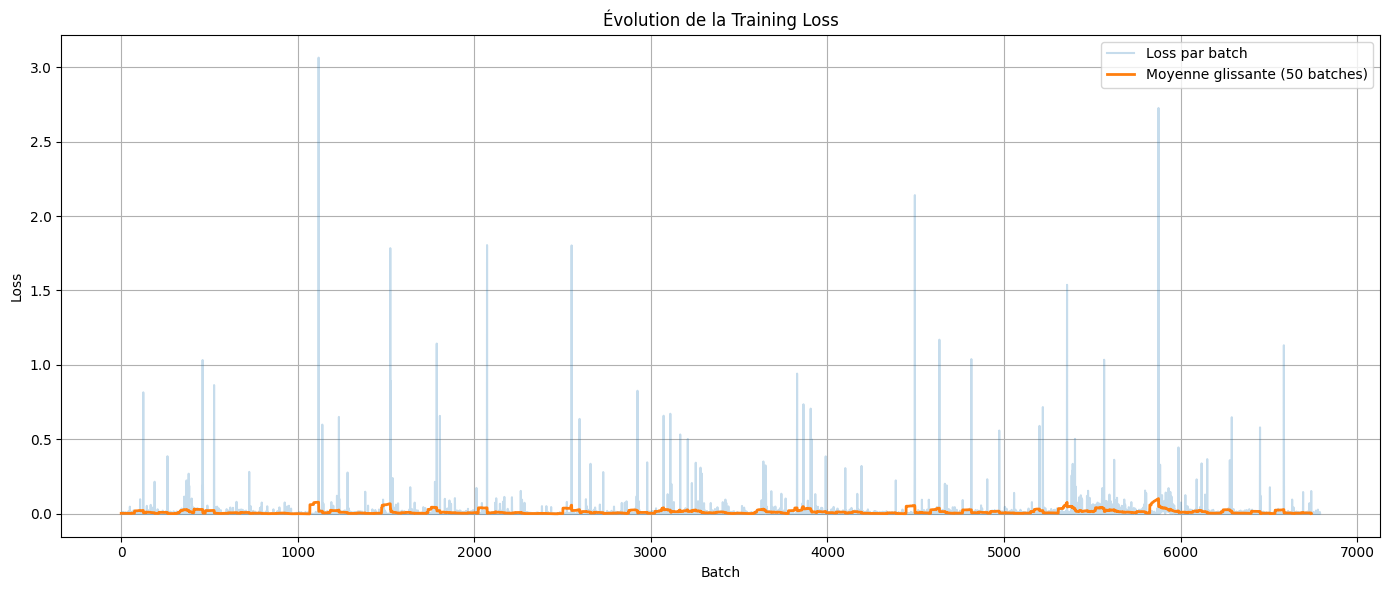

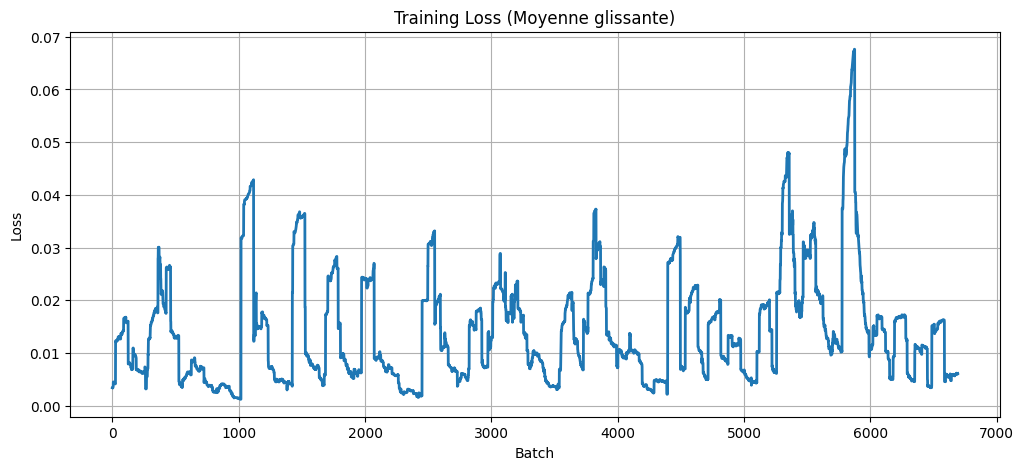

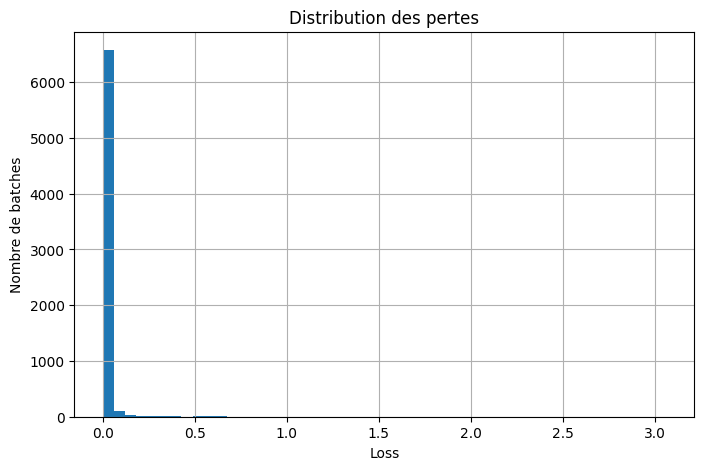

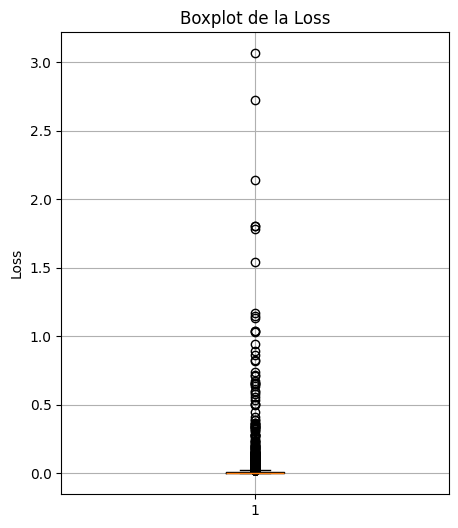

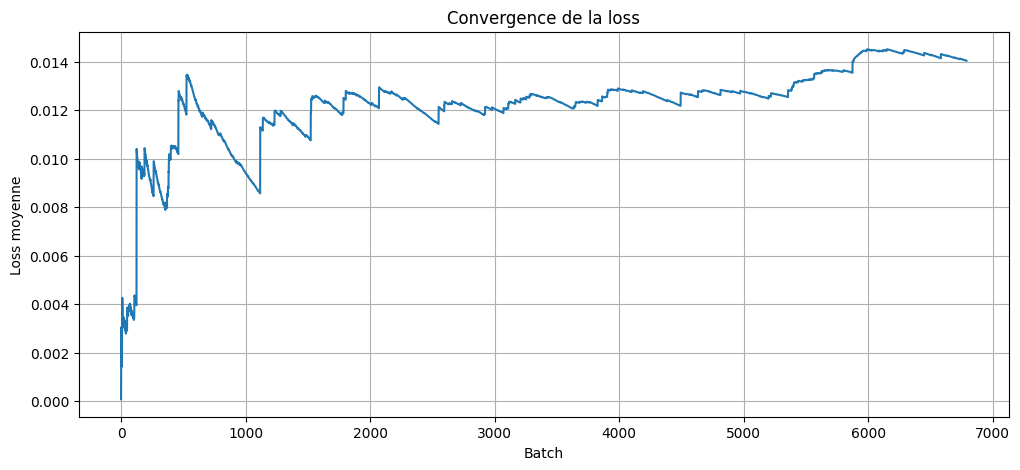

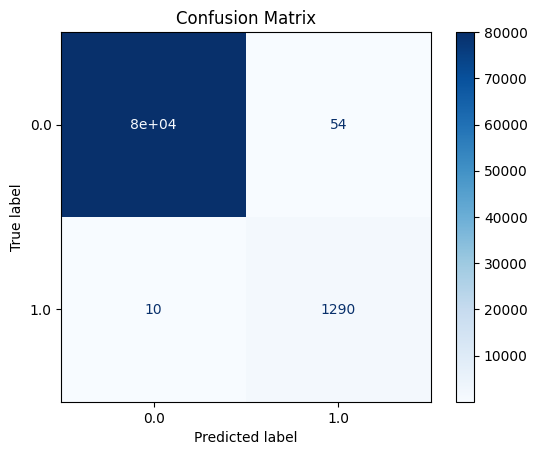

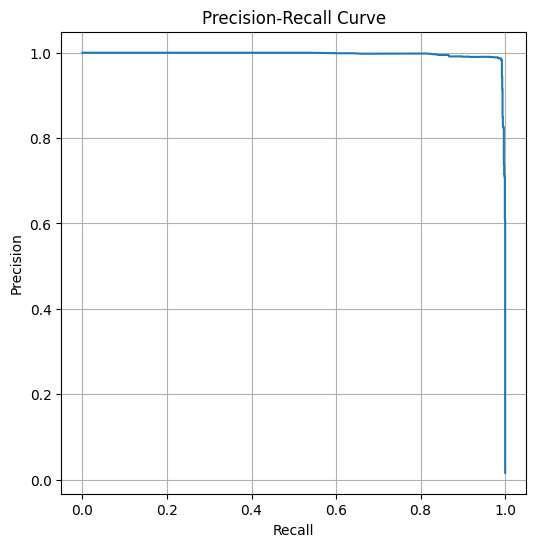

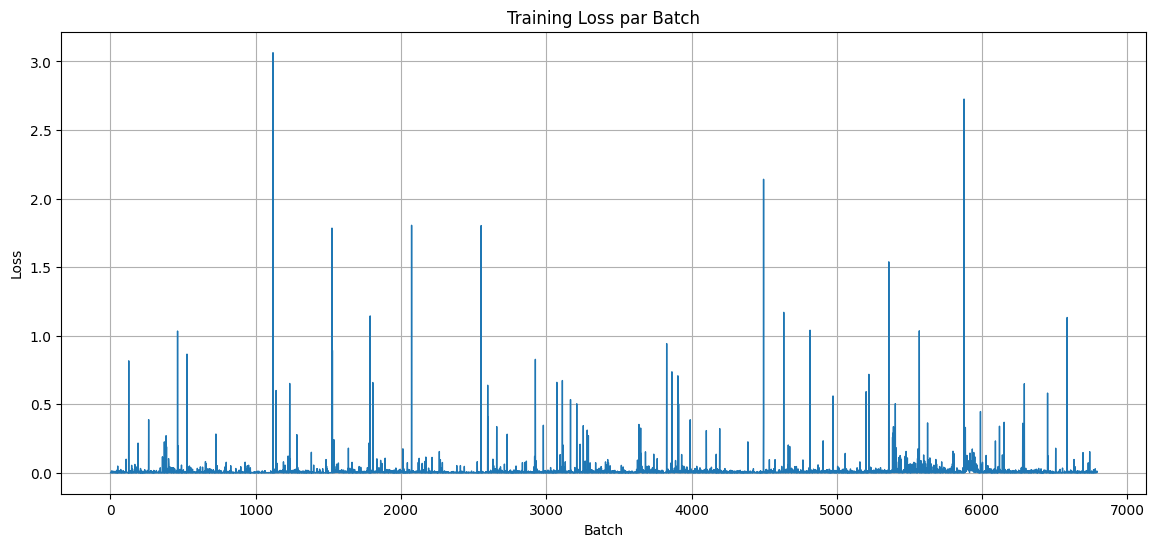

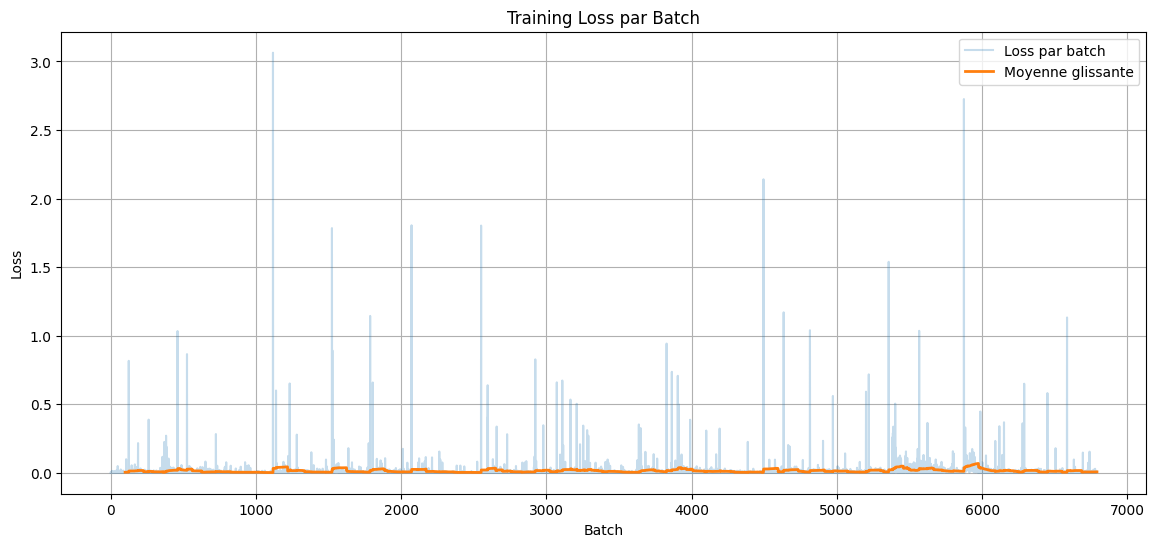

STATISTIQUES DES LOSSES PAR BATCH
Nombre de batches : 6791
Loss minimale     : 0.000000
Loss maximale     : 3.063338
Loss moyenne      : 0.014043
Écart-type        : 0.090265


In [86]:
# ============================================================
# PARTIE 6 : ENTRAÎNEMENT DU MODÈLE
# ============================================================

from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
import time

print("=" * 70)
print("PARTIE 6 : ENTRAÎNEMENT DU BiLSTM")
print("=" * 70)

num_epochs = 1

history = {
    "train_loss": [],
    "val_loss": [],
    "accuracy": [],
    "precision": [],
    "recall": [],
    "f1": []
}

training_start = time.time()
# Historique de la loss par batch
batch_losses = []

for epoch in range(num_epochs):

    epoch_start = time.time()

    print(f"\nEpoch {epoch+1}/{num_epochs}")

    # =====================================================
    # TRAIN
    # =====================================================

    model.train()

    running_loss = 0.0

    train_bar = tqdm(
        train_loader,
        desc=f"Train {epoch+1}/{num_epochs}",
        leave=False
    )

    for batch in train_bar:

        sequences = batch["sequence"].to(device)
        numeric = batch["numeric"].to(device)
        labels = batch["label"].to(device)

        optimizer.zero_grad()

        outputs = model(sequences, numeric)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        # Loss du batch courant
        current_loss = loss.item()

        # Sauvegarde pour le graphique
        batch_losses.append(current_loss)

        # Affichage dans tqdm
        train_bar.set_postfix({
            "Batch Loss": f"{current_loss:.6f}"
        })

    train_loss = running_loss / len(train_loader)

    # =====================================================
    # VALIDATION
    # =====================================================

    model.eval()

    val_loss = 0.0

    y_true = []
    y_pred = []
    y_scores = []

    val_bar = tqdm(
        val_loader,
        desc="Validation",
        leave=False
    )

    with torch.no_grad():

        for batch in val_bar:

            sequences = batch["sequence"].to(device)
            numeric = batch["numeric"].to(device)
            labels = batch["label"].to(device)

            outputs = model(sequences, numeric)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            probs = torch.sigmoid(outputs)

            preds = (probs >= 0.5).float()

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
            y_scores.extend(probs.cpu().numpy())

            val_bar.set_postfix(
                loss=f"{val_loss/(val_bar.n+1):.4f}"
            )

    val_loss /= len(val_loader)

    # =====================================================
    # MÉTRIQUES
    # =====================================================

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    # =====================================================
    # Scheduler + EarlyStopping
    # =====================================================

    scheduler.step(val_loss)

    early_stopping(val_loss, model)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["accuracy"].append(accuracy)
    history["precision"].append(precision)
    history["recall"].append(recall)
    history["f1"].append(f1)

    current_lr = optimizer.param_groups[0]["lr"]

    epoch_time = time.time() - epoch_start

    elapsed = time.time() - training_start

    avg_epoch = elapsed / (epoch + 1)

    eta = avg_epoch * (num_epochs - epoch - 1)

    # =====================================================
    # AFFICHAGE
    # =====================================================

    print("=" * 70)

    print(f"Epoch           : {epoch+1}/{num_epochs}")

    print(f"Train Loss      : {train_loss:.4f}")
    print(f"Validation Loss : {val_loss:.4f}")

    print()

    print(f"Accuracy        : {accuracy:.4f}")
    print(f"Precision       : {precision:.4f}")
    print(f"Recall          : {recall:.4f}")
    print(f"F1-score        : {f1:.4f}")

    print()

    print(f"Learning Rate   : {current_lr:.6f}")

    print(f"Temps époque    : {epoch_time:.1f} sec")

    print(f"ETA             : {eta/60:.1f} min")

    print("=" * 70)

    if early_stopping.early_stop:

        print("\n🛑 Early Stopping déclenché.")

        break

print("\n" + "=" * 70)
print("✓ Entraînement terminé.")
print("=" * 70)
# ============================================================
# COURBE DE LA LOSS PAR BATCH
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

window = 50

# Moyenne glissante
smooth_loss = np.convolve(
    batch_losses,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(14,6))

plt.plot(
    batch_losses,
    alpha=0.25,
    label="Loss par batch"
)

plt.plot(
    smooth_loss,
    linewidth=2,
    label=f"Moyenne glissante ({window} batches)"
)

plt.title("Évolution de la Training Loss")
plt.xlabel("Batch")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()
window = 100

smooth = np.convolve(
    batch_losses,
    np.ones(window)/window,
    mode="valid"
)

plt.figure(figsize=(12,5))
plt.plot(smooth, linewidth=2)
plt.xlabel("Batch")
plt.ylabel("Loss")
plt.title("Training Loss (Moyenne glissante)")
plt.grid(True)
plt.show()
plt.figure(figsize=(8,5))

plt.hist(
    batch_losses,
    bins=50
)

plt.xlabel("Loss")
plt.ylabel("Nombre de batches")
plt.title("Distribution des pertes")
plt.grid(True)

plt.show()
plt.figure(figsize=(5,6))

plt.boxplot(batch_losses)

plt.ylabel("Loss")

plt.title("Boxplot de la Loss")

plt.grid(True)

plt.show()
cum_loss = np.cumsum(batch_losses) / np.arange(1, len(batch_losses)+1)

plt.figure(figsize=(12,5))

plt.plot(cum_loss)

plt.xlabel("Batch")
plt.ylabel("Loss moyenne")

plt.title("Convergence de la loss")

plt.grid(True)

plt.show()
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.show()
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(
    y_true,
    y_scores
)

plt.figure(figsize=(6,6))

plt.plot(recall, precision)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("Precision-Recall Curve")

plt.grid(True)

plt.show()
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

plt.plot(
    range(1, len(batch_losses)+1),
    batch_losses,
    linewidth=1
)

plt.title("Training Loss par Batch")
plt.xlabel("Batch")
plt.ylabel("Loss")
plt.grid(True)

plt.show()
import numpy as np
import matplotlib.pyplot as plt

window = 100

smooth_loss = np.convolve(
    batch_losses,
    np.ones(window)/window,
    mode="valid"
)

plt.figure(figsize=(14,6))

plt.plot(batch_losses, alpha=0.25, label="Loss par batch")

plt.plot(
    range(window, len(batch_losses)+1),
    smooth_loss,
    linewidth=2,
    label="Moyenne glissante"
)

plt.title("Training Loss par Batch")
plt.xlabel("Batch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()
import numpy as np

print("=" * 60)
print("STATISTIQUES DES LOSSES PAR BATCH")
print("=" * 60)

print(f"Nombre de batches : {len(batch_losses)}")
print(f"Loss minimale     : {np.min(batch_losses):.6f}")
print(f"Loss maximale     : {np.max(batch_losses):.6f}")
print(f"Loss moyenne      : {np.mean(batch_losses):.6f}")
print(f"Écart-type        : {np.std(batch_losses):.6f}")

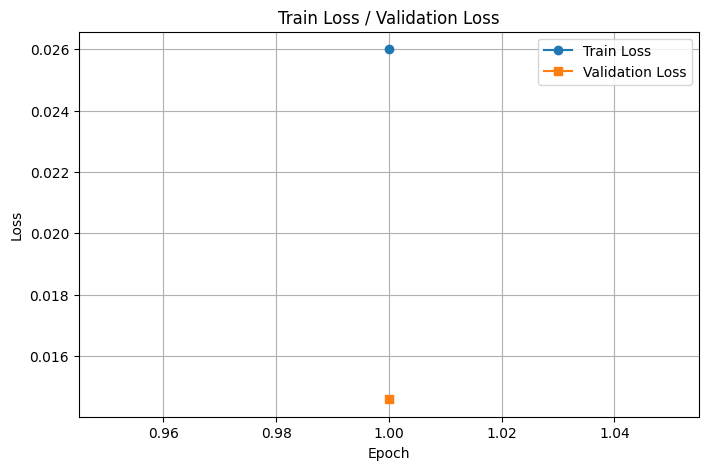

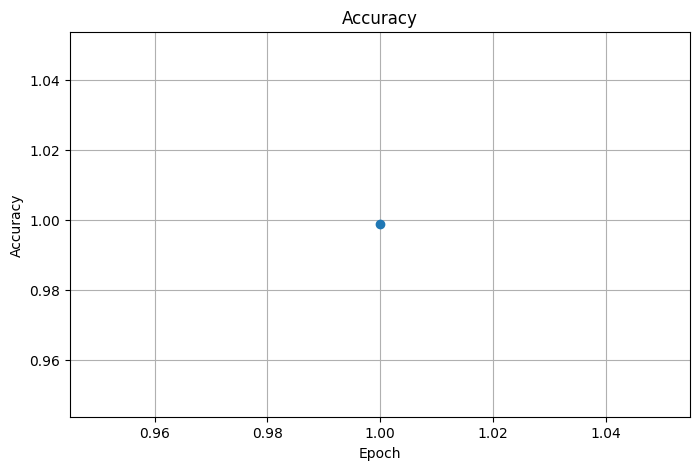

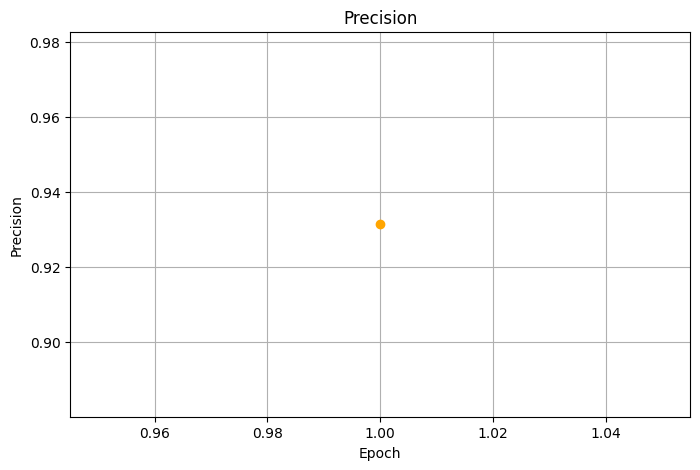

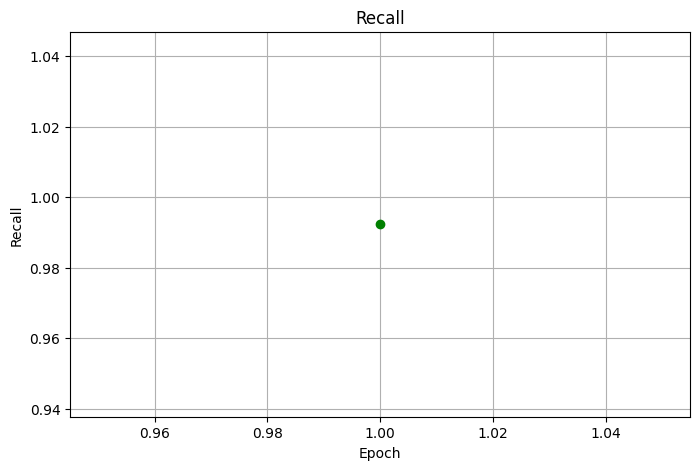

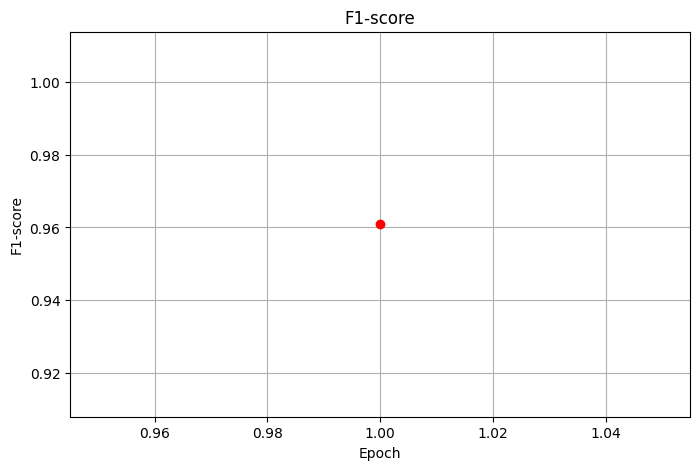

In [76]:
# ============================================================
# VISUALISATION DE L'ENTRAÎNEMENT
# ============================================================

import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------

plt.figure(figsize=(8,5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train Loss / Validation Loss")
plt.grid(True)
plt.legend()

plt.show()

# ------------------------------------------------------------
# Accuracy
# ------------------------------------------------------------

plt.figure(figsize=(8,5))

plt.plot(
    epochs,
    history["accuracy"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.grid(True)

plt.show()

# ------------------------------------------------------------
# Precision
# ------------------------------------------------------------

plt.figure(figsize=(8,5))

plt.plot(
    epochs,
    history["precision"],
    marker="o",
    color="orange"
)

plt.xlabel("Epoch")
plt.ylabel("Precision")
plt.title("Precision")
plt.grid(True)

plt.show()

# ------------------------------------------------------------
# Recall
# ------------------------------------------------------------

plt.figure(figsize=(8,5))

plt.plot(
    epochs,
    history["recall"],
    marker="o",
    color="green"
)

plt.xlabel("Epoch")
plt.ylabel("Recall")
plt.title("Recall")
plt.grid(True)

plt.show()

# ------------------------------------------------------------
# F1-score
# ------------------------------------------------------------

plt.figure(figsize=(8,5))

plt.plot(
    epochs,
    history["f1"],
    marker="o",
    color="red"
)

plt.xlabel("Epoch")
plt.ylabel("F1-score")
plt.title("F1-score")
plt.grid(True)

plt.show()

In [1]:
# ============================================================
# PARTIE 7 : ÉVALUATION DU MODÈLE SUR LE JEU DE TEST
# ============================================================

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    auc
)

import matplotlib.pyplot as plt
import numpy as np
import torch

print("=" * 70)
print("PARTIE 7 : ÉVALUATION DU MODÈLE")
print("=" * 70)

# ------------------------------------------------------------
# Charger le meilleur modèle sauvegardé
# ------------------------------------------------------------

model.load_state_dict(torch.load("./best_bilstm_model.pth", map_location=device))
model.eval()

print("✓ Meilleur modèle chargé")

# ------------------------------------------------------------
# Prédictions
# ------------------------------------------------------------

y_true = []
y_pred = []
y_prob = []

with torch.no_grad():

    for batch in test_loader:

        sequences = batch["sequence"].to(device)
        numeric = batch["numeric"].to(device)
        labels = batch["label"].to(device)

        outputs = model(sequences, numeric)

        probs = torch.sigmoid(outputs)

        preds = (probs >= 0.5).float()

        y_true.extend(labels.cpu().numpy())

        y_pred.extend(preds.cpu().numpy())

        y_prob.extend(probs.cpu().numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred).astype(int)
y_prob = np.array(y_prob)
print("=" * 60)
print("EXEMPLES DE PRÉDICTIONS")
print("=" * 60)

for i in range(20):
    print(
        f"Vrai={int(y_true[i])} | "
        f"Probabilité={float(y_prob[i]):.10f} | "
        f"Prédit={int(y_pred[i])}"
    )
# ------------------------------------------------------------
# Vérification des probabilités
# ------------------------------------------------------------

print("Nombre de scores différents :", len(np.unique(y_prob)))

print("\nQuelques probabilités faibles :")
print(np.sort(y_prob)[:20])

print("\nQuelques probabilités élevées :")
print(np.sort(y_prob)[-20:])


# Distribution des scores
plt.figure(figsize=(8,5))

plt.hist(y_prob[y_true==0], bins=50, alpha=0.5, label="Normal")
plt.hist(y_prob[y_true==1], bins=50, alpha=0.5, label="Anomaly")

plt.xlabel("Probability")
plt.ylabel("Count")
plt.title("Distribution des probabilités BiLSTM")

plt.legend()
plt.grid(True)

plt.show()

# ------------------------------------------------------------
# Métriques
# ------------------------------------------------------------

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(y_true, y_pred)

recall = recall_score(y_true, y_pred)

f1 = f1_score(y_true, y_pred)

roc_auc = roc_auc_score(y_true, y_prob)

precision_curve, recall_curve, _ = precision_recall_curve(
    y_true,
    y_prob
)

pr_auc = auc(recall_curve, precision_curve)

print("\nRésultats")

print("-" * 50)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print(f"PR-AUC    : {pr_auc:.4f}")

# ------------------------------------------------------------
# Classification Report
# ------------------------------------------------------------

print("\nClassification Report")

print(classification_report(
    y_true,
    y_pred,
    target_names=["Normal", "Anomaly"]
))

# ------------------------------------------------------------
# Matrice de confusion
# ------------------------------------------------------------

cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix")

print(cm)

# ------------------------------------------------------------
# Courbe ROC
# ------------------------------------------------------------

fpr, tpr, _ = roc_curve(y_true, y_prob)

plt.figure(figsize=(7,6))

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")

plt.plot([0,1],[0,1],'--')

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.grid(True)

plt.show()

# ------------------------------------------------------------
# Courbe Precision-Recall
# ------------------------------------------------------------

plt.figure(figsize=(7,6))

plt.plot(recall_curve, precision_curve,
         label=f"PR-AUC = {pr_auc:.4f}")

plt.xlabel("Recall")

plt.ylabel("Precision")

plt.title("Precision-Recall Curve")

plt.legend()

plt.grid(True)

plt.show()

print("=" * 70)
print("ÉVALUATION TERMINÉE")
print("=" * 70)

PARTIE 7 : ÉVALUATION DU MODÈLE


NameError: name 'model' is not defined